In [3]:
# ==========================================
# 0. Instalação de Dependências
# ==========================================
!pip install deap google-genai scikit-learn pandas numpy matplotlib seaborn

In [4]:
# ==========================================
# Importações das Bibliotecas
# ==========================================
import os
import random
import time
import logging
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score, recall_score, f1_score, precision_score, confusion_matrix, classification_report
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split

# Biblioteca para Algoritmos Genéticos
from deap import base, creator, tools, algorithms

# Configuração de Logging para Monitoramento
logging.basicConfig(
    level=logging.INFO,
    format='%(asctime)s - %(levelname)s - %(message)s',
    handlers=[
        logging.FileHandler("pipeline_diagnostic.log"),
        logging.StreamHandler()
    ]
)
logger = logging.getLogger(__name__)


In [6]:
# Carregamento do dataframe
df = pd.read_csv('data.csv')
all_headers = df.columns.tolist()

X = df.iloc[:, :-1]
y = df.iloc[:, -1]

print("Detected Columns:", all_headers)
cols_to_drop = ['id', 'Unnamed: 32']
df_clean = df.drop(columns=[col for col in cols_to_drop if col in df.columns])

 # Malignant = 1, Benign = 0
y = df_clean['diagnosis'].map({'M': 1, 'B': 0})
X = df_clean.drop(columns=['diagnosis'])

# Usado apenas para analize e não treino
df_clean['diagnosis'] = df_clean['diagnosis'].map({'M': 1, 'B': 0})

print("Cleaned Features (X) shape:", X.shape)
print("Cleaned Target (y) shape:", y.shape)

X_train, X_test, y_train, y_test = train_test_split(
    X, y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

print(f"X_train shape: {X_train.shape}")  # (455 samples, 30 features)
print(f"X_test shape:  {X_test.shape}")   # (114 samples, 30 features)
print(f"y_train shape: {y_train.shape}")  # (455 labels)
print(f"y_test shape:  {y_test.shape}")   # (114 labels)

Detected Columns: ['id', 'diagnosis', 'radius_mean', 'texture_mean', 'perimeter_mean', 'area_mean', 'smoothness_mean', 'compactness_mean', 'concavity_mean', 'concave points_mean', 'symmetry_mean', 'fractal_dimension_mean', 'radius_se', 'texture_se', 'perimeter_se', 'area_se', 'smoothness_se', 'compactness_se', 'concavity_se', 'concave points_se', 'symmetry_se', 'fractal_dimension_se', 'radius_worst', 'texture_worst', 'perimeter_worst', 'area_worst', 'smoothness_worst', 'compactness_worst', 'concavity_worst', 'concave points_worst', 'symmetry_worst', 'fractal_dimension_worst', 'Unnamed: 32']
Cleaned Features (X) shape: (569, 30)
Cleaned Target (y) shape: (569,)
X_train shape: (455, 30)
X_test shape:  (114, 30)
y_train shape: (455,)
y_test shape:  (114,)


In [10]:
# Normalização das Features (Boa prática para pipeline ML)
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

# Model Baseline (Sem Otimização)
baseline_model = RandomForestClassifier(random_state=42)
baseline_model.fit(X_train_scaled, y_train)
y_pred_base = baseline_model.predict(X_test_scaled)

print("=== DESEMPENHO DO MODELO BASELINE ===")
print(f"Accuracy:  {accuracy_score(y_test, y_pred_base):.4f}")
print(f"Recall:    {recall_score(y_test, y_pred_base):.4f}")
print(f"F1-Score:  {f1_score(y_test, y_pred_base):.4f}\n")

# --- DEFINIÇÃO DO ALGORITMO GENÉTICO (DEAP) ---
# Fitness: Maximizar F1-Score (importante para falso-negativos em oncologia)
if "FitnessMax" in creator.__dict__:
    del creator.FitnessMax
if "Individual" in creator.__dict__:
    del creator.Individual

creator.create("FitnessMax", base.Fitness, weights=(1.0,))
creator.create("Individual", list, fitness=creator.FitnessMax)

toolbox = base.Toolbox()

# Genes (Codificação)
toolbox.register("n_estimators", random.randint, 10, 200)
toolbox.register("max_depth", random.randint, 2, 20)
toolbox.register("min_samples_split", random.randint, 2, 10)
toolbox.register("min_samples_leaf", random.randint, 1, 10)

# Individuo e População
toolbox.register("individual", tools.initCycle, creator.Individual,
                 (toolbox.n_estimators, toolbox.max_depth, toolbox.min_samples_split, toolbox.min_samples_leaf), n=1)
toolbox.register("population", tools.initRepeat, list, toolbox.individual)

# Função Fitness
def evaluate_individual(individual):
    n_est, max_d, min_split, min_leaf = individual
    model = RandomForestClassifier(
        n_estimators=int(n_est),
        max_depth=int(max_d),
        min_samples_split=int(min_split),
        min_samples_leaf=int(min_leaf),
        random_state=42
    )
    model.fit(X_train_scaled, y_train)
    preds = model.predict(X_test_scaled)
    # Fitness baseada no F1-Score ponderado pela sensibilidade (Recall)
    score = f1_score(y_test, preds)
    return (score,)

# Operadores Genéticos
toolbox.register("evaluate", evaluate_individual)
toolbox.register("mate", tools.cxTwoPoint)
toolbox.register("mutate", tools.mutUniformInt, low=[10, 2, 2, 1], up=[200, 20, 10, 10], indpb=0.2)
toolbox.register("select", tools.selTournament, tournsize=3)

# --- EXECUÇÃO DOS 3 EXPERIMENTOS ---
experimentos_config = [
    {"exp": 1, "pop_size": 10, "ngen": 5, "cxpb": 0.5, "mutpb": 0.2},
    {"exp": 2, "pop_size": 20, "ngen": 10, "cxpb": 0.7, "mutpb": 0.3},
    {"exp": 3, "pop_size": 40, "ngen": 15, "cxpb": 0.8, "mutpb": 0.1}
]

resultados_experimentos = []

for config in experimentos_config:
    logger.info(f"Iniciando Experimento {config['exp']}...")
    start_time = time.time()

    pop = toolbox.population(n=config["pop_size"])
    hof = tools.HallOfFame(1)

    stats = tools.Statistics(lambda ind: ind.fitness.values)
    stats.register("max", np.max)
    stats.register("avg", np.mean)

    pop, logbook = algorithms.eaSimple(
        pop, toolbox,
        cxpb=config["cxpb"],
        mutpb=config["mutpb"],
        ngen=config["ngen"],
        stats=stats,
        halloffame=hof,
        verbose=False
    )

    exec_time = time.time() - start_time
    best_ind = hof[0]
    best_f1 = best_ind.fitness.values[0]

    # Treinar modelo final com os melhores parâmetros do experimento
    best_model = RandomForestClassifier(
        n_estimators=int(best_ind[0]),
        max_depth=int(best_ind[1]),
        min_samples_split=int(best_ind[2]),
        min_samples_leaf=int(best_ind[3]),
        random_state=42
    )
    best_model.fit(X_train_scaled, y_train)
    y_pred_opt = best_model.predict(X_test_scaled)

    res = {
        "Experimento": f"Exp {config['exp']}",
        "População": config["pop_size"],
        "Gerações": config["ngen"],
        "Taxa Mutação": config["mutpb"],
        "Melhores Hiperparâmetros (n_est, max_d, min_split, min_leaf)": best_ind,
        "Accuracy": accuracy_score(y_test, y_pred_opt),
        "Recall": recall_score(y_test, y_pred_opt),
        "F1-Score": f1_score(y_test, y_pred_opt),
        "Tempo (s)": round(exec_time, 2)
    }
    resultados_experimentos.append(res)
    logger.info(f"Experimento {config['exp']} Concluído. F1: {res['F1-Score']:.4f} em {res['Tempo (s)']}s")

# Tabela de Comparação
df_res = pd.DataFrame(resultados_experimentos)
display(df_res)

=== DESEMPENHO DO MODELO BASELINE ===
Accuracy:  0.9737
Recall:    0.9286
F1-Score:  0.9630



,Experimento,População,Gerações,Taxa Mutação,"Melhores Hiperparâmetros (n_est, max_d, min_split, min_leaf)",Accuracy,Recall,F1-Score,Tempo (s)
0,Exp 1,10,5,0.2,"[192, 15, 5, 1]",0.973684,0.928571,0.962963,15.15
1,Exp 2,20,10,0.3,"[140, 6, 6, 1]",0.973684,0.928571,0.962963,66.23
2,Exp 3,40,15,0.1,"[165, 18, 9, 1]",0.973684,0.928571,0.962963,197.03



Melhor Experimento Selecionado: Exp 2


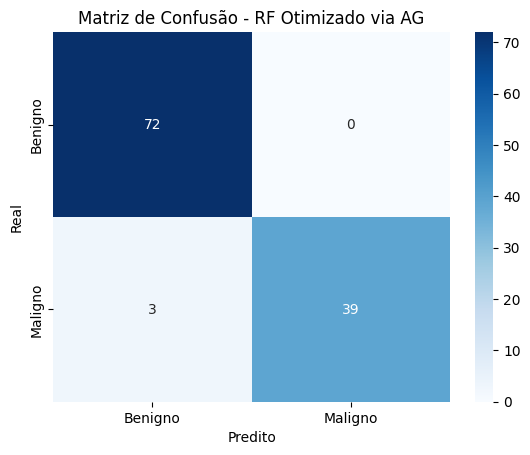

In [8]:
# ==========================================
# Logging de Metricas e Tracking de Desempenho
# ==========================================
def avaliar_e_logar_modelo(model, X_test, y_test, nome_modelo="Modelo Otimizado"):
    start = time.time()
    y_pred = model.predict(X_test)
    inference_time = (time.time() - start) / len(X_test)

    acc = accuracy_score(y_test, y_pred)
    rec = recall_score(y_test, y_pred)
    f1 = f1_score(y_test, y_pred)
    prec = precision_score(y_test, y_pred)

    logger.info(f"--- RELATÓRIO DE MONITORAMENTO: {nome_modelo} ---")
    logger.info(f"Acurácia: {acc:.4f} | Recall: {rec:.4f} | Precision: {prec:.4f} | F1: {f1:.4f}")
    logger.info(f"Tempo médio de inferência por amostra: {inference_time*1000:.2f} ms")

    # Matriz de Confusão
    cm = confusion_matrix(y_test, y_pred)
    sns.heatmap(cm, annot=True, fmt='d', cmap='Blues', xticklabels=['Benigno', 'Maligno'], yticklabels=['Benigno', 'Maligno'])
    plt.title(f'Matriz de Confusão - {nome_modelo}')
    plt.ylabel('Real')
    plt.xlabel('Predito')
    plt.show()

# Testando monitoramento no melhor modelo treinado
melhor_exp = df_res.loc[df_res['F1-Score'].idxmax()]
print(f"\nMelhor Experimento Selecionado: {melhor_exp['Experimento']}")

# Re-treinando o melhor modelo global
best_params = melhor_exp['Melhores Hiperparâmetros (n_est, max_d, min_split, min_leaf)']
final_model = RandomForestClassifier(
    n_estimators=int(best_params[0]),
    max_depth=int(best_params[1]),
    min_samples_split=int(best_params[2]),
    min_samples_leaf=int(best_params[3]),
    random_state=42
)
final_model.fit(X_train_scaled, y_train)

avaliar_e_logar_modelo(final_model, X_test_scaled, y_test, nome_modelo="RF Otimizado via AG")

In [12]:
import os
from google import genai
from google.genai import types

# Obtém a API Key dos Secrets do Colab ou da variável de ambiente
GEMINI_API_KEY = os.getenv("GEMINI_API_KEY", "GEMINI_KEY")

def gerar_explicacao_diagnostico_gemini(dados_paciente, predicao_classe, probabilidade, modelo_llm="gemini-3.1-flash-lite"):
    """
    Integra a predição do modelo de ML com o Google Gemini usando Prompt Engineering.
    """
    status_diag = "Maligno (Suspeita de Câncer de Mama)" if predicao_classe == 1 else "Benigno (Sem Evidência de Malignidade)"

    system_instruction = (
        "Você é um assistente médico especialista em oncologia e análise de exames citopatológicos de mama. "
        "Sua tarefa é traduzir métricas estatísticas de um modelo de Machine Learning "
        "em um laudo explicativo clínico claro, objetivo e acionável para o médico responsável. "
        "Não emita diagnósticos definitivos; apresente os dados estritamente como suporte à decisão clínica."
    )

    user_prompt = f"""
    --- DADOS DO PACIENTE E PREDIÇÃO DE ML ---
    - Diagnóstico Predito pelo Modelo: {status_diag}
    - Probabilidade de Malignidade: {probabilidade * 100:.2f}%

    --- PRINCIPAIS CARACTERÍSTICAS BIOMÉTRICAS DO EXAME ---
    - Raio Médio das Células: {dados_paciente.get('radius_mean', 'N/A')}
    - Textura Média: {dados_paciente.get('texture_mean', 'N/A')}
    - Perímetro Médio: {dados_paciente.get('perimeter_mean', 'N/A')}
    - Área Média: {dados_paciente.get('area_mean', 'N/A')}
    - Concavidade Pior (Concavity Worst): {dados_paciente.get('concavity_worst', 'N/A')}

    Por favor, gere um relatório estruturado em 3 tópicos:
    1. **Resumo Clínico da Predição**: Explicação sumária da decisão do modelo.
    2. **Análise dos Biomarcadores**: Como os valores numéricos fornecidos influenciaram a probabilidade calculada.
    3. **Recomendações e Próximos Passos**: Sugestões médicas acionáveis (ex: biópsia, acompanhamento, exames complementares).
    """


    try:
        # Inicializa o cliente do Gemini
        client = genai.Client(api_key=GEMINI_API_KEY)

        response = client.models.generate_content(
            model=modelo_llm,
            contents=user_prompt,
            config=types.GenerateContentConfig(
                system_instruction=system_instruction,
                temperature=0.3
            )
        )
        return response.text
    except Exception as e:
        return f"Erro na chamada da API do Gemini: {str(e)}"

# --- EXECUTANDO A GERAÇÃO DE RELATÓRIO COM O GEMINI ---
idx_amostra = 2
paciente_valores = X_test.iloc[idx_amostra].to_dict()
paciente_scaled = X_test_scaled[idx_amostra].reshape(1, -1)

predicao = final_model.predict(paciente_scaled)[0]
probabilidade_maligno = final_model.predict_proba(paciente_scaled)[0][1]

relatorio_gemini = gerar_explicacao_diagnostico_gemini(paciente_valores, predicao, probabilidade_maligno)

print("\n=======================================================")
print("  RELATÓRIO GERADO PELO GOOGLE GEMINI PARA O MÉDICO    ")
print("=======================================================\n")
print(relatorio_gemini)


  RELATÓRIO GERADO PELO GOOGLE GEMINI PARA O MÉDICO    

Este relatório tem caráter estritamente informativo e serve como suporte à decisão clínica, não substituindo a avaliação médica presencial ou o laudo anatomopatológico definitivo.

---

### 1. Resumo Clínico da Predição
O modelo de aprendizado de máquina classificou a amostra como **Benigna**, com uma probabilidade calculada de malignidade de **28,99%**. 

Embora a predição aponte para a ausência de malignidade, a probabilidade de 28,99% situa-se em uma zona de atenção. Em contextos de triagem citopatológica, este valor é superior ao limiar de ruído estatístico, sugerindo que, embora os padrões morfológicos predominantes sejam compatíveis com benignidade, existem características celulares que se desviam da normalidade esperada. O resultado deve ser interpretado com cautela, considerando o histórico clínico e a correlação com exames de imagem (BI-RADS).

### 2. Análise dos Biomarcadores
Os parâmetros morfológicos fornecidos apres